Ishak 1...4


In [ ]:
# Role: install the libraries required for downloading the dataset, manipulating arrays, and processing images.
!pip install -q kagglehub pandas pillow tqdm

In [ ]:
# Role: import the necessary tools, download the COCO 2017 dataset from Kaggle, and store its local path in the variable `path`.
import kagglehub
import os

# Download dataset from Kaggle
path = kagglehub.dataset_download("awsaf49/coco-2017-dataset")

print("Dataset downloaded successfully!")
print("Dataset path:", path)

Using Colab cache for faster access to the 'coco-2017-dataset' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/coco-2017-dataset


In [ ]:
# Role: explore the dataset directory structure to understand where the downloaded images and files are located.

import os

for root, dirs, files in os.walk(path):
    print("Folder:", root)
    print("Number of files:", len(files))
    print("Examples:", files[:5])
    if root.count(os.sep) - path.count(os.sep) >= 2:
        dirs[:] = []

Folder: /kaggle/input/coco-2017-dataset
Number of files: 0
Examples: []
Folder: /kaggle/input/coco-2017-dataset/coco2017
Number of files: 0
Examples: []
Folder: /kaggle/input/coco-2017-dataset/coco2017/val2017
Number of files: 5000
Examples: ['000000011197.jpg', '000000219485.jpg', '000000151000.jpg', '000000371677.jpg', '000000038825.jpg']
Folder: /kaggle/input/coco-2017-dataset/coco2017/annotations
Number of files: 6
Examples: ['person_keypoints_train2017.json', 'instances_val2017.json', 'instances_train2017.json', 'person_keypoints_val2017.json', 'captions_train2017.json']
Folder: /kaggle/input/coco-2017-dataset/coco2017/test2017
Number of files: 40670
Examples: ['000000355443.jpg', '000000081349.jpg', '000000436639.jpg', '000000210548.jpg', '000000196829.jpg']
Folder: /kaggle/input/coco-2017-dataset/coco2017/train2017
Number of files: 118287
Examples: ['000000501175.jpg', '000000094632.jpg', '000000276721.jpg', '000000113282.jpg', '000000452819.jpg']


In [ ]:
# Role: automatically locate the train2017/val2017 directories as well as the JSON files containing the annotations.

import os

image_folders = []
json_files = []

for root, dirs, files in os.walk(path):
    if "train2017" in root or "val2017" in root:
        image_folders.append(root)

    for file in files:
        if file.endswith(".json"):
            json_files.append(os.path.join(root, file))

print("Image folders:", image_folders)
print("JSON files:", json_files)

Image folders: ['/kaggle/input/coco-2017-dataset/coco2017/val2017', '/kaggle/input/coco-2017-dataset/coco2017/train2017']
JSON files: ['/kaggle/input/coco-2017-dataset/coco2017/annotations/person_keypoints_train2017.json', '/kaggle/input/coco-2017-dataset/coco2017/annotations/instances_val2017.json', '/kaggle/input/coco-2017-dataset/coco2017/annotations/instances_train2017.json', '/kaggle/input/coco-2017-dataset/coco2017/annotations/person_keypoints_val2017.json', '/kaggle/input/coco-2017-dataset/coco2017/annotations/captions_train2017.json', '/kaggle/input/coco-2017-dataset/coco2017/annotations/captions_val2017.json']


In [ ]:
# Role: Identify the training and validation image directories, then list the available image files.

from PIL import Image
import os

train_dir = None
val_dir = None

for folder in image_folders:
    if os.path.basename(folder) == "train2017":
        train_dir = folder
    elif os.path.basename(folder) == "val2017":
        val_dir = folder

train_images = [
    f for f in os.listdir(train_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

val_images = [
    f for f in os.listdir(val_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

Training images: 118287
Validation images: 5000


In [ ]:
# Role: reconstruct the expected paths to train2017 and val2017, then verify that these directories exist.

import os
from PIL import Image

train_dir = os.path.join(path, "coco2017", "train2017")
val_dir = os.path.join(path, "coco2017", "val2017")

print("Train directory:", train_dir)
print("Validation directory:", val_dir)

print("Train exists:", os.path.exists(train_dir))
print("Validation exists:", os.path.exists(val_dir))

Train directory: /kaggle/input/coco-2017-dataset/coco2017/train2017
Validation directory: /kaggle/input/coco-2017-dataset/coco2017/val2017
Train exists: True
Validation exists: True


In [ ]:
# Role: create three distinct sets of images: 10,000 for the knowledge base, 100 for validation, and 1,000 for testing.

import random
import pandas as pd

random.seed(42)

# Select 10,000 knowledge base images
knowledge_images = random.sample(train_images, 10000)

# Select 100 validation images from remaining images
remaining_images = list(set(train_images) - set(knowledge_images))
validation_images = random.sample(remaining_images, 100)

# Select 1,000 test images from COCO val2017
test_images = random.sample(val_images, 1000)

print("Knowledge Base:", len(knowledge_images))
print("Validation:", len(validation_images))
print("Test:", len(test_images))

Knowledge Base: 10000
Validation: 100
Test: 1000


In [ ]:
# Role: save the image names for each set into CSV files to preserve the dataset splits.

os.makedirs("/content/COCO_splits", exist_ok=True)

pd.DataFrame({"image": knowledge_images}).to_csv(
    "/content/COCO_splits/knowledge_base.csv", index=False
)

pd.DataFrame({"image": validation_images}).to_csv(
    "/content/COCO_splits/validation.csv", index=False
)

pd.DataFrame({"image": test_images}).to_csv(
    "/content/COCO_splits/test.csv", index=False
)

print("Splits saved successfully!")

Splits saved successfully!


In [ ]:
# Role: verify that no images are shared between the sets, in order to limit data leakage.


assert set(knowledge_images).isdisjoint(validation_images)
assert set(knowledge_images).isdisjoint(test_images)
assert set(validation_images).isdisjoint(test_images)

print("Anti-leakage check: PASSED")

Anti-leakage check: PASSED


In [ ]:
# Role: define a preprocessing function that corrects the EXIF ​​orientation,
#converts the image to RGB, and resizes it to a maximum of 224×224.

from PIL import Image, ImageOps
import os

output_dir = "/content/COCO_processed"
os.makedirs(output_dir, exist_ok=True)

def preprocess_image(image_path, output_path):
    img = Image.open(image_path)

    # Correct EXIF orientation
    img = ImageOps.exif_transpose(img)

    # Convert to RGB
    img = img.convert("RGB")

    # Resize while preserving aspect ratio
    img.thumbnail((224, 224))

    img.save(output_path, "JPEG")

print("Preprocessing function ready!")

Preprocessing function ready!


In [ ]:
# Role: apply preprocessing to all images in the three sets
# and save the processed copies into separate folders.

for split_name, images, source_dir in [
    ("knowledge_base", knowledge_images, train_dir),
    ("validation", validation_images, train_dir),
    ("test", test_images, val_dir)
]:

    split_dir = os.path.join(output_dir, split_name)
    os.makedirs(split_dir, exist_ok=True)

    for filename in images:
        input_path = os.path.join(source_dir, filename)
        output_path = os.path.join(split_dir, filename)

        preprocess_image(input_path, output_path)

    print(split_name, "completed:", len(images))

knowledge_base completed: 10000
validation completed: 100
test completed: 1000


In [ ]:
# Role: display the paths and names of the detected JSON files to facilitate their identification.

for file in json_files:
    print(os.path.basename(file), ":", file)

person_keypoints_train2017.json : /kaggle/input/coco-2017-dataset/coco2017/annotations/person_keypoints_train2017.json
instances_val2017.json : /kaggle/input/coco-2017-dataset/coco2017/annotations/instances_val2017.json
instances_train2017.json : /kaggle/input/coco-2017-dataset/coco2017/annotations/instances_train2017.json
person_keypoints_val2017.json : /kaggle/input/coco-2017-dataset/coco2017/annotations/person_keypoints_val2017.json
captions_train2017.json : /kaggle/input/coco-2017-dataset/coco2017/annotations/captions_train2017.json
captions_val2017.json : /kaggle/input/coco-2017-dataset/coco2017/annotations/captions_val2017.json


In [ ]:
# Role: Load COCO caption annotations for train2017 and val2017, then display the number of available captions.

import json

train_caption_file = next(
    f for f in json_files if "captions_train2017" in f
)

val_caption_file = next(
    f for f in json_files if "captions_val2017" in f
)

with open(train_caption_file, "r") as f:
    train_data = json.load(f)

with open(val_caption_file, "r") as f:
    val_data = json.load(f)

print("Training captions:", len(train_data["annotations"]))
print("Validation captions:", len(val_data["annotations"]))

Training captions: 591753
Validation captions: 25014


In [ ]:
# Role: define the cleaning of captions and a function that associates the captions with the identifiers of the selected images.

import re

def clean_caption(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s]", "", text)
    return text.strip()

def prepare_captions(data, selected_images):
    selected_ids = {
        int(os.path.splitext(name)[0])
        for name in selected_images
    }

    captions = []

    for annotation in data["annotations"]:
        if annotation["image_id"] in selected_ids:
            raw = annotation["caption"]

            captions.append({
                "image_id": annotation["image_id"],
                "raw_caption": raw,
                "cleaned_caption": clean_caption(raw)
            })

    return pd.DataFrame(captions)

In [ ]:
# Rôle : extraire les légendes correspondant à chaque ensemble et
#sauvegarder les légendes brutes et nettoyées dans des fichiers CSV.

kb_captions = prepare_captions(train_data, knowledge_images)
val_captions = prepare_captions(train_data, validation_images)
test_captions = prepare_captions(val_data, test_images)

kb_captions.to_csv("/content/COCO_splits/kb_captions.csv", index=False)
val_captions.to_csv("/content/COCO_splits/val_captions.csv", index=False)
test_captions.to_csv("/content/COCO_splits/test_captions.csv", index=False)

print("Knowledge Base captions:", len(kb_captions))
print("Validation captions:", len(val_captions))
print("Test captions:", len(test_captions))

Knowledge Base captions: 50034
Validation captions: 500
Test captions: 5003


In [ ]:
# Role: display an overall summary of the number of
# images and captions in each set, as well as the status of the leakage check.

print("========== FINAL REPORT ==========")

print("Knowledge Base images:", len(knowledge_images))
print("Validation images:", len(validation_images))
print("Test images:", len(test_images))

print("\nKnowledge Base captions:", len(kb_captions))
print("Validation captions:", len(val_captions))
print("Test captions:", len(test_captions))

# print("\nCorrupted train images:", len(bad_train))
# print("Corrupted val images:", len(bad_val))

print("\nAnti-leakage:", "PASSED")

print("\nPreprocessing completed!")

========== FINAL REPORT ==========
Knowledge Base images: 10000
Validation images: 100
Test images: 1000

Knowledge Base captions: 50034
Validation captions: 500
Test captions: 5003

Anti-leakage: PASSED

Preprocessing completed!


# Ramy 5 and 6


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
import os
import json
from ultralytics import YOLO
from tqdm import tqdm

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
model = YOLO("yolov8n.pt")

In [ ]:
images_dir = '/kaggle/input/coco-2017-dataset/coco2017/train2017'

In [ ]:
metadata_dict = {}

In [ ]:
if os.path.exists(images_dir):
    image_files = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    print(f"Found {len(image_files)} images. Starting fast metadata extraction...")

    image_paths = [os.path.join(images_dir, f) for f in image_files]
    batch_size = 32


    for i in tqdm(range(0, len(image_paths), batch_size), desc="Extracting Metadata Batches"):
        batch_paths = image_paths[i:i+batch_size]
        batch_names = image_files[i:i+batch_size]


        results = model(batch_paths, conf=0.25, verbose=False)

        for img_name, r in zip(batch_names, results):
            image_objects = []
            boxes = r.boxes
            for box in boxes:
                cls_id = int(box.cls[0])
                cls_name = model.names[cls_id]
                confidence = float(box.conf[0])
                xyxy = box.xyxy[0].tolist()

                image_objects.append({
                    "object_name": cls_name,
                    "confidence": round(confidence, 4),
                    "bounding_box": [round(coord, 2) for coord in xyxy]
                })

            metadata_dict[img_name] = {
                "image_id": img_name,
                "detected_objects": image_objects,
                "object_count": len(image_objects)
            }

    output_json_path = "/content/coco_metadata_output.json"
    with open(output_json_path, 'w', encoding='utf-8') as f:
        json.dump(metadata_dict, f, ensure_ascii=False, indent=4)

    print(f"\nMetadata extraction completed successfully! Saved to {output_json_path}")
else:
    print(f"The directory {images_dir} does not exist. Please check the path.")

Found 118287 images. Starting fast metadata extraction...


Extracting Metadata Batches: 100%|██████████| 3697/3697 [35:01<00:00,  1.76it/s]



Metadata extraction completed successfully! Saved to /content/coco_metadata_output.json


In [ ]:
!pip install -q faiss-cpu
%pip install open-clip-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 11.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [open-clip-torch]


In [ ]:
import os
import torch
import open_clip
import numpy as np
from PIL import Image
from tqdm import tqdm

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
model.eval()
model.to(device)

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(32, 32), stride=(32, 32), bias=False)
    (patch_dropout): Identity()
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (transformer): Transformer(
      (resblocks): ModuleList(
        (0-11): 12 x ResidualAttentionBlock(
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (attn): Attention(
            (ln_q): Identity()
            (ln_k): Identity()
            (attn_drop): Dropout(p=0.0, inplace=False)
            (ln_inner): Identity()
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_drop): Dropout(p=0.0, inplace=False)
          )
          (ls_1): Identity()
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): GELU(approximate='none'

In [ ]:
images_dir = '/kaggle/input/coco-2017-dataset/coco2017/train2017'

In [ ]:
image_embeddings_list = []
image_filenames = []

In [ ]:
if os.path.exists(images_dir):
    image_files = [f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    print(f"Found {len(image_files)} images. Starting Embedding Generation...")

    with torch.no_grad():
        for img_name in tqdm(image_files, desc="Generating Embeddings"):
            img_path = os.path.join(images_dir, img_name)

            try:

                image = preprocess(Image.open(img_path)).unsqueeze(0).to(device)


                image_features = model.encode_image(image)


                image_features /= image_features.norm(dim=-1, keepdim=True)


                image_embeddings_list.append(image_features.cpu().numpy())
                image_filenames.append(img_name)

            except Exception as e:
                print(f"Error processing {img_name}: {e}")


    if image_embeddings_list:
        all_embeddings = np.vstack(image_embeddings_list)


        output_embeddings_path = "/content/coco_image_embeddings.npy"
        output_filenames_path = "/content/coco_image_filenames.npy"

        np.save(output_embeddings_path, all_embeddings)
        np.save(output_filenames_path, np.array(image_filenames))

        print("\n Embedding Generation Completed Successfully!")
        print(f"Saved embeddings matrix shape (Dimensions & Size): {all_embeddings.shape}")
        print(f"Embeddings saved to: {output_embeddings_path}")
        print(f"Filenames saved to: {output_filenames_path}")
    else:
        print("No valid images were processed.")
else:
    print(f"The directory {images_dir} does not exist. Please check the path.")

Found 118287 images. Starting Embedding Generation...


Generating Embeddings: 100%|██████████| 118287/118287 [43:05<00:00, 45.74it/s]



 Embedding Generation Completed Successfully!
Saved embeddings matrix shape (Dimensions & Size): (118287, 512)
Embeddings saved to: /content/coco_image_embeddings.npy
Filenames saved to: /content/coco_image_filenames.npy


# Islem 7 and 8


In [ ]:
# STEP 7: Knowledge-Base Construction

!pip install -q faiss-cpu

In [ ]:
import faiss
import numpy as np
import pandas as pd
import os
import json
import time

In [ ]:
# Role: Load the image embeddings and corresponding image filenames from the knowledge base.

import numpy as np

# Load image embeddings
all_embeddings = np.load("/content/coco_image_embeddings.npy")

# Load image filenames
image_filenames = np.load(
    "/content/coco_image_filenames.npy",
    allow_pickle=True
)

# Convert embeddings to float32 for consistency and efficient storage
all_embeddings = all_embeddings.astype("float32")

# Display the number and shape of loaded embeddings
print("Embeddings shape:", all_embeddings.shape)
print("Number of image filenames:", len(image_filenames))

Embeddings shape: (118287, 512)
Number of image filenames: 118287


In [ ]:
# Role: Create a FAISS vector index using the image embeddings for efficient similarity search.

# Get the embedding dimension
dimension = all_embeddings.shape[1]

# Create a Flat index using Inner Product similarity
index = faiss.IndexFlatIP(dimension)

# Measure the indexing time
start_time = time.time()

# Add all image embeddings to the FAISS index
index.add(all_embeddings)

# Calculate the total indexing time
indexing_time = time.time() - start_time

# Display the index information
print("FAISS index created successfully!")
print("Index type: Flat")
print("Similarity metric: Inner Product (Cosine)")
print("Number of vectors:", index.ntotal)
print("Embedding dimension:", dimension)
print("Indexing time:", round(indexing_time, 2), "seconds")

FAISS index created successfully!
Index type: Flat
Similarity metric: Inner Product (Cosine)
Number of vectors: 118287
Embedding dimension: 512
Indexing time: 0.26 seconds


In [ ]:
# Role: Build the knowledge base by linking image embeddings to filenames, image IDs, captions, and metadata.

# Create a DataFrame containing vector IDs and image filenames
knowledge_base = pd.DataFrame({
    "vector_id": range(len(image_filenames)),
    "image_filename": image_filenames
})

# Extract image IDs from image filenames
knowledge_base["image_id"] = knowledge_base["image_filename"].apply(
    lambda x: int(os.path.splitext(str(x))[0])
)

# Merge the image captions with the knowledge base
knowledge_base = knowledge_base.merge(
    kb_captions[["image_id", "raw_caption", "cleaned_caption"]],
    on="image_id",
    how="left"
)

# Load image metadata from the JSON file
metadata_path = "/content/coco_metadata_output.json"

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata_dict = json.load(f)

# Associate each image with its corresponding metadata
knowledge_base["metadata"] = knowledge_base["image_filename"].map(
    metadata_dict
)

# Display the first 5 rows of the knowledge base
print(knowledge_base.head())

   vector_id    image_filename  image_id raw_caption cleaned_caption  \
0          0  000000501175.jpg    501175         NaN             NaN   
1          1  000000094632.jpg     94632         NaN             NaN   
2          2  000000276721.jpg    276721         NaN             NaN   
3          3  000000113282.jpg    113282         NaN             NaN   
4          4  000000452819.jpg    452819         NaN             NaN   

                                            metadata  
0  {'image_id': '000000501175.jpg', 'detected_obj...  
1  {'image_id': '000000094632.jpg', 'detected_obj...  
2  {'image_id': '000000276721.jpg', 'detected_obj...  
3  {'image_id': '000000113282.jpg', 'detected_obj...  
4  {'image_id': '000000452819.jpg', 'detected_obj...  


In [ ]:
# Role: Create the knowledge base metadata by linking image IDs to captions and metadata, then save it as a JSON file.

# Create a DataFrame containing vector IDs and image filenames
knowledge_base = pd.DataFrame({
    "vector_id": range(len(image_filenames)),
    "image_filename": image_filenames
})

# Extract image IDs from image filenames
knowledge_base["image_id"] = knowledge_base["image_filename"].apply(
    lambda x: int(os.path.splitext(str(x))[0])
)

# Create a mapping between image IDs and their corresponding captions
caption_mapping = (
    kb_captions.groupby("image_id")["raw_caption"]
    .apply(list)
    .to_dict()
)

# Associate each image with its captions
knowledge_base["captions"] = knowledge_base["image_id"].map(
    caption_mapping
)

# Associate each image with its corresponding metadata
knowledge_base["metadata"] = knowledge_base["image_filename"].map(
    metadata_dict
)

# Save the knowledge-base metadata as a JSON file
knowledge_base.to_json(
    "/content/knowledge_base_metadata.json",
    orient="records",
    indent=2
)

# Display a confirmation message
print("Knowledge-base metadata saved!")

Knowledge-base metadata saved!


In [ ]:
# Role: Save the FAISS index and image embeddings to files for future use.

# Save the FAISS index
faiss.write_index(index, "/content/coco_faiss.index")

# Save the image embeddings as a NumPy file
np.save(
    "/content/coco_image_embeddings.npy",
    all_embeddings
)

# Calculate the FAISS index file size in megabytes
index_size = os.path.getsize("/content/coco_faiss.index") / (1024 * 1024)

# Display the saving confirmation and index size
print("FAISS index saved successfully!")
print("Index size:", round(index_size, 2), "MB")

FAISS index saved successfully!
Index size: 231.03 MB


In [ ]:
# STEP 8: Quality Control

# Role: Perform quality control checks on image embeddings, filenames, captions, and metadata.

print("========== QUALITY CONTROL ==========")

print("Missing embeddings:", np.isnan(all_embeddings).any())

print("NaN values:", np.isnan(all_embeddings).sum())
print("Infinite values:", np.isinf(all_embeddings).sum())

print("Duplicate filenames:", pd.Series(image_filenames).duplicated().sum())

print("Duplicate image IDs:", knowledge_base["image_id"].duplicated().sum())

print("Missing metadata:", knowledge_base["metadata"].isna().sum())

print("Missing captions:", knowledge_base["captions"].isna().sum())

print("Embedding count:", len(all_embeddings))
print("Filename count:", len(image_filenames))

# Ensure that embeddings and filenames have matching counts
assert len(all_embeddings) == len(image_filenames)

# Ensure that embeddings contain no NaN or infinite values
assert not np.isnan(all_embeddings).any()
assert not np.isinf(all_embeddings).any()

print("Basic QC completed!")

========== QUALITY CONTROL ==========
Missing embeddings: False
NaN values: 0
Infinite values: 0
Duplicate filenames: 0
Duplicate image IDs: 0
Missing metadata: 0
Missing captions: 108287
Embedding count: 118287
Filename count: 118287
Basic QC completed!


In [ ]:
# Role: Check caption consistency by identifying images in the knowledge base that do not have corresponding captions.

# Extract all image IDs available in the captions dataset
caption_ids = set(kb_captions["image_id"])

# Extract image IDs from the embedding filenames
embedding_ids = set(
    int(os.path.splitext(str(filename))[0])
    for filename in image_filenames
)

# Identify images that have embeddings but no corresponding captions
caption_mismatches = embedding_ids - caption_ids

# Display the number of images without captions
print("Images without captions:", len(caption_mismatches))

Images without captions: 108287


In [ ]:
# Role: Perform a data leakage audit to verify that knowledge-base, validation, and test datasets contain no overlapping images.

# Convert image lists into sets for efficient comparison
knowledge_ids = set(knowledge_images)
validation_ids = set(validation_images)
test_ids = set(test_images)

# Check for overlapping images between the datasets
print("Knowledge/Validation overlap:",
      len(knowledge_ids & validation_ids))

print("Knowledge/Test overlap:",
      len(knowledge_ids & test_ids))

print("Validation/Test overlap:",
      len(validation_ids & test_ids))

# Ensure that all three datasets are completely separate
assert knowledge_ids.isdisjoint(validation_ids)
assert knowledge_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)

# Display the leakage audit result
print("Leakage audit: PASSED")

Knowledge/Validation overlap: 0
Knowledge/Test overlap: 0
Validation/Test overlap: 0
Leakage audit: PASSED


In [ ]:
# Role: Analyze the frequency of detected object classes and measure scene complexity across the knowledge base images.

from collections import Counter

# Initialize a counter for object frequencies and a list for scene complexity
object_counts = Counter()
scene_complexity = []

# Process metadata for each image
for filename in image_filenames:

    # Retrieve metadata for the current image
    image_metadata = metadata_dict.get(str(filename), {})

    # Extract detected objects from image metadata
    detected_objects = image_metadata.get("detected_objects", [])

    # Calculate the number of detected objects in the image
    scene_complexity.append(len(detected_objects))

    # Count the occurrences of each detected object class
    for obj in detected_objects:
        object_counts[obj["object_name"]] += 1

# Create a DataFrame containing object classes and their frequencies
object_frequency = pd.DataFrame(
    object_counts.items(),
    columns=["Object Class", "Frequency"]
).sort_values("Frequency", ascending=False)

# Display the 10 most frequent object classes
print(object_frequency.head(10))

# Calculate and display scene complexity statistics
print("Average objects per image:", np.mean(scene_complexity))
print("Maximum objects in one image:", np.max(scene_complexity))

    Object Class  Frequency
5         person     225229
36           car      31543
7          chair      24162
17        bottle      16053
1            cup      14544
22  dining table      13031
2           bowl      11644
38      umbrella       9192
41         sheep       8387
55          kite       8128
Average objects per image: 5.48362880113622
Maximum objects in one image: 75


Average caption length: 10.442738937522485
Maximum caption length: 47
Vocabulary size: 10026


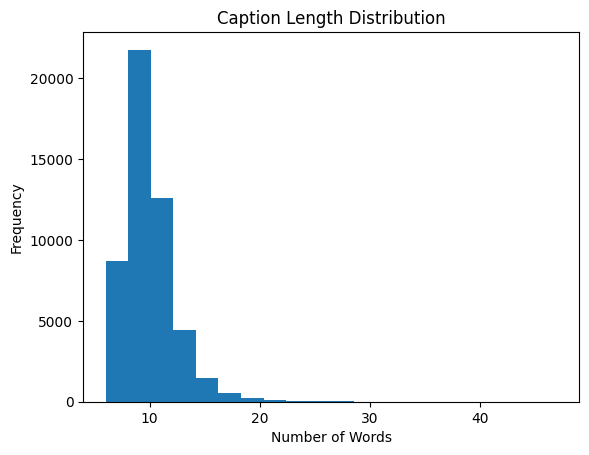

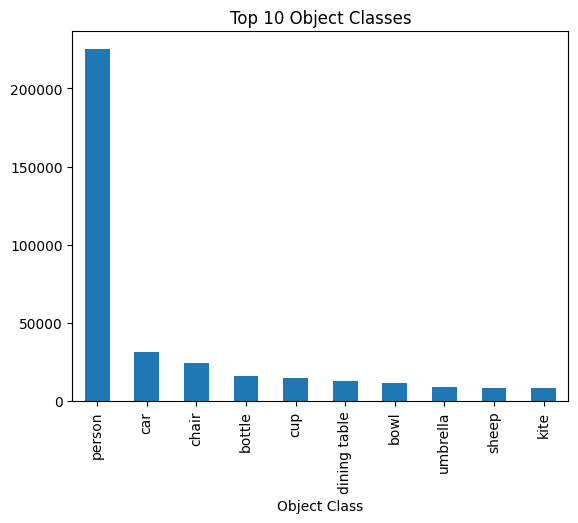

In [ ]:
# Role: Analyze caption statistics, measure vocabulary size, and visualize caption length distribution and the most frequent object classes.

import matplotlib.pyplot as plt

# Calculate the number of words in each cleaned caption
kb_captions["caption_length"] = (
    kb_captions["cleaned_caption"].str.split().str.len()
)

# Display caption length statistics
print("Average caption length:",
      kb_captions["caption_length"].mean())

print("Maximum caption length:",
      kb_captions["caption_length"].max())

# Build a vocabulary containing all unique words from the captions
vocabulary = set()

for caption in kb_captions["cleaned_caption"]:
    vocabulary.update(caption.split())

# Display the total vocabulary size
print("Vocabulary size:", len(vocabulary))

# Visualize the distribution of caption lengths
plt.hist(kb_captions["caption_length"], bins=20)
plt.title("Caption Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

# Visualize the 10 most frequent object classes
object_frequency.head(10).plot(
    x="Object Class",
    y="Frequency",
    kind="bar",
    legend=False
)

plt.title("Top 10 Object Classes")
plt.show()

In [ ]:
!pip install -q nltk

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


   POS Tag  Frequency
1       NN     154282
0       DT     107334
5       IN      83975
4       JJ      41671
6      NNS      31576
2      VBG      30504
3      VBZ      13424
13      CC      12084
11     VBN       6873
9       CD       6334
8      VBP       5685
16      TO       5642
7     PRP$       4009
10      RP       3781
21      RB       3444


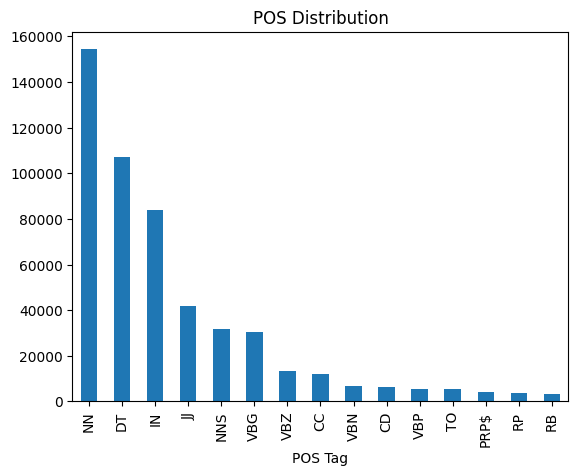

In [ ]:
# Role: Perform Part-of-Speech (POS) analysis on cleaned captions to identify the frequency of different grammatical categories and visualize the results.

import nltk
from nltk import word_tokenize, pos_tag
from collections import Counter

# Download the required NLTK resources
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger_eng")

# Initialize a counter to store POS tag frequencies
pos_counts = Counter()

# Process each cleaned caption
for caption in kb_captions["cleaned_caption"].dropna():

    # Tokenize the caption into individual words
    words = word_tokenize(caption)

    # Assign a Part-of-Speech tag to each word
    tagged_words = pos_tag(words)

    # Count the occurrences of each POS tag
    for word, tag in tagged_words:
        pos_counts[tag] += 1

# Create a DataFrame containing POS tags and their frequencies
pos_df = pd.DataFrame(
    pos_counts.items(),
    columns=["POS Tag", "Frequency"]
).sort_values("Frequency", ascending=False)

# Display the 15 most frequent POS tags
print(pos_df.head(15))

# Visualize the distribution of the 15 most frequent POS tags
pos_df.head(15).plot(
    x="POS Tag",
    y="Frequency",
    kind="bar",
    legend=False
)

# Add chart title and display the visualization
plt.title("POS Distribution")
plt.show()

In [ ]:
# Role: Testing the FAISS image retrieval system by searching for the 5 most similar images to a selected query image.

# Select the first image embedding as the query vector
query_vector = all_embeddings[0:1]

# Search the FAISS index for the 5 most similar image embeddings
distances, indices = index.search(query_vector, 5)

# Display the top 5 retrieved images
print("Top 5 retrieved images:")

for rank, vector_id in enumerate(indices[0]):

    # Retrieve the filename corresponding to the vector ID
    filename = image_filenames[vector_id]

    # Display the image filename and similarity score
    print(
        f"Rank {rank + 1}: {filename} "
        f"| Similarity: {distances[0][rank]:.4f}"
    )

# Verify that the query image is retrieved as the first result
assert indices[0][0] == 0

# Display the retrieval validation result
print("Retrieval validation: PASSED")

Top 5 retrieved images:
Rank 1: 000000501175.jpg | Similarity: 1.0000
Rank 2: 000000203035.jpg | Similarity: 0.9233
Rank 3: 000000248712.jpg | Similarity: 0.9175
Rank 4: 000000218988.jpg | Similarity: 0.9047
Rank 5: 000000302147.jpg | Similarity: 0.9007
Retrieval validation: PASSED


In [ ]:
# Role: Implement a text-to-image search function using CLIP embeddings and FAISS to retrieve the most similar images based on a text query.

# Initialize the CLIP tokenizer
tokenizer = open_clip.get_tokenizer("ViT-B-32")

# Define a function to search for images using a text query
def search_images(query, top_k=5):

    # Convert the text query into tokens
    text_tokens = tokenizer([query]).to(device)

    # Generate text embeddings using the CLIP model
    with torch.no_grad():

        text_features = model.encode_text(text_tokens)

        # Normalize text embeddings for cosine similarity
        text_features /= text_features.norm(
            dim=-1, keepdim=True
        )

    # Convert text embeddings to float32 NumPy arrays
    text_features = text_features.cpu().numpy().astype("float32")

    # Search the FAISS index for the most similar image embeddings
    scores, indices = index.search(text_features, top_k)

    # Initialize a list to store the search results
    results = []

    # Retrieve image filenames, similarity scores, and captions
    for score, idx in zip(scores[0], indices[0]):

        filename = str(image_filenames[idx])

        results.append({
            "image": filename,
            "similarity": float(score),
            "captions": caption_mapping.get(
                int(os.path.splitext(filename)[0]), []
            )
        })

    # Return the search results as a DataFrame
    return pd.DataFrame(results)

In [ ]:
# Role: Analyze the lexical diversity of cleaned captions by calculating the total number of words, unique words, and lexical diversity.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Extract cleaned captions and remove missing values
captions = kb_captions["cleaned_caption"].dropna().astype(str)

# Collect all words from the captions
all_words = []

for caption in captions:
    all_words.extend(caption.lower().split())

# Identify all unique words in the captions
unique_words = set(all_words)

# Calculate lexical diversity
lexical_diversity = len(unique_words) / len(all_words) if all_words else 0

# Display lexical diversity statistics
print("Total words:", len(all_words))
print("Unique words:", len(unique_words))
print("Lexical Diversity:", round(lexical_diversity, 4))

Total words: 522492
Unique words: 10026
Lexical Diversity: 0.0192


,Word,Frequency
0,a,82353
1,on,18243
2,of,17049
3,the,16601
4,in,15373
5,with,13117
6,and,11926
7,is,8259
8,man,6138
9,to,5642


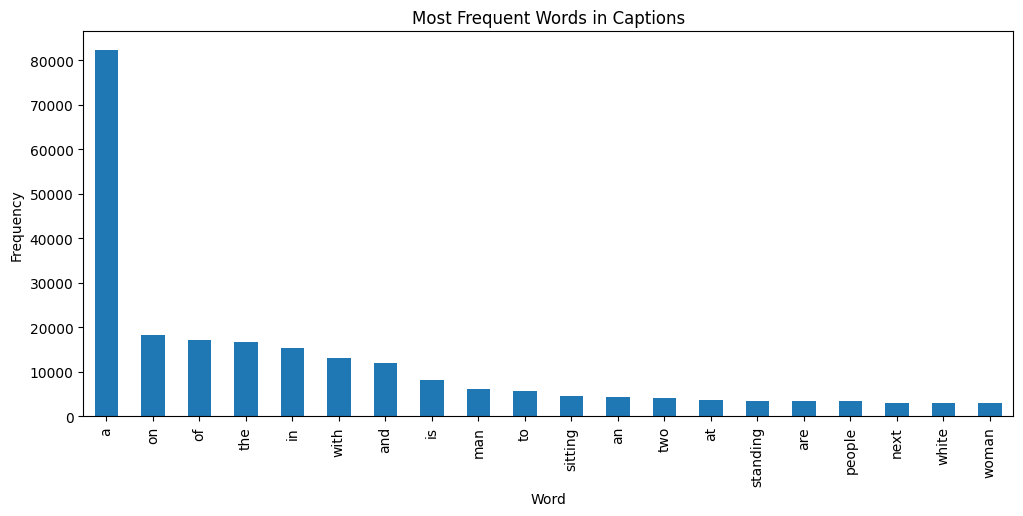

In [ ]:
# Role: Analyze word frequency in cleaned captions and visualize the 20 most frequently used words.

# Count the occurrences of each word in all captions
word_frequency = Counter(all_words)

# Create a DataFrame containing the 20 most frequent words and their frequencies
most_common_words = pd.DataFrame(
    word_frequency.most_common(20),
    columns=["Word", "Frequency"]
)

# Display the most frequent words
display(most_common_words)

# Visualize the 20 most frequent words
most_common_words.plot(
    x="Word",
    y="Frequency",
    kind="bar",
    figsize=(12, 5),
    legend=False
)

# Add chart title and axis label
plt.title("Most Frequent Words in Captions")
plt.ylabel("Frequency")

# Display the chart
plt.show()

In [ ]:
# Role: Calculate semantic diversity by finding the average similarity between a random sample of image embeddings.

from sklearn.metrics.pairwise import cosine_similarity

# Select a sample of up to 1,000 image embeddings
sample_size = min(1000, len(all_embeddings))

# Set a random seed for reproducibility
np.random.seed(42)

# Randomly select image indices without replacement
sample_indices = np.random.choice(
    len(all_embeddings),
    sample_size,
    replace=False
)

# Extract the selected image embeddings
sample_embeddings = all_embeddings[sample_indices]

# Calculate the cosine similarity matrix between sampled embeddings
similarity_matrix = cosine_similarity(sample_embeddings)

# Extract the upper triangle values, excluding the diagonal
upper_triangle = similarity_matrix[
    np.triu_indices(sample_size, k=1)
]

# Calculate the average cosine similarity
mean_similarity = np.mean(upper_triangle)

# Calculate semantic diversity
semantic_diversity = 1 - mean_similarity

# Display semantic diversity results
print("Average Cosine Similarity:", round(mean_similarity, 4))
print("Semantic Diversity:", round(semantic_diversity, 4))

Average Cosine Similarity: 0.5133
Semantic Diversity: 0.4867


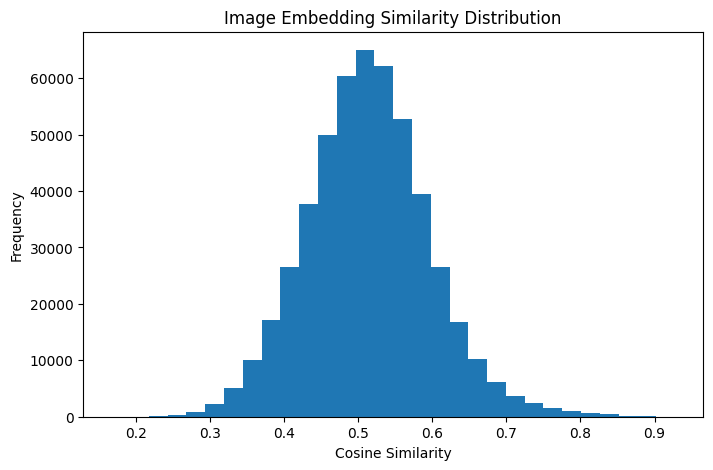

In [ ]:
# Role: Visualize the distribution of cosine similarity scores between image embeddings to analyze semantic diversity.

plt.figure(figsize=(8, 5))

plt.hist(upper_triangle, bins=30)

plt.title("Image Embedding Similarity Distribution")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")

# Display the histogram
plt.show()

In [ ]:
# Role: Show the lexical and semantic diversity results and explain what they tell us about the dataset.

print("========== DIVERSITY ANALYSIS ==========")

# Display the calculated diversity scores
print("Lexical Diversity:", round(lexical_diversity, 4))
print("Semantic Diversity:", round(semantic_diversity, 4))

# Interpret lexical diversity
if lexical_diversity > 0.5:
    print("Captions contain a relatively varied vocabulary.")
else:
    print("Captions show more vocabulary repetition.")

# Interpret semantic diversity
if semantic_diversity > 0.3:
    print("Images show relatively high semantic diversity.")
else:
    print("Images show relatively low semantic diversity.")

========== DIVERSITY ANALYSIS ==========
Lexical Diversity: 0.0192
Semantic Diversity: 0.4867
Captions show more vocabulary repetition.
Images show relatively high semantic diversity.
